<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/customerchurn_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assignment 1: Decision Tree Optimization for Customer Churn Prediction
Objective: Build and optimize a Decision Tree classifier to predict customer churn based on behavioral data.

Dataset: Assignment-Dataset/assignment1_decision_tree_optimization.csv

Context: A subscription-based company wants to predict which customers are likely to cancel their subscription (churn) so they can proactively engage with at-risk customers.

Instructions:
Import necessary libraries
Load and preprocess the dataset
Perform exploratory data analysis (EDA) to understand the data
Separate features (Age, Annual_Income, Spending_Score, Years_as_Customer, Online_Purchase_Frequency) and target (Will_Churn)
Split the data into training (80%) and test (20%) sets with random_state=42
Build a Decision Tree classifier with criterion='entropy' and random_state=0
Experiment with different max_depth values (2, 4, 6, 8, 10, None)
For each max_depth value, calculate:
Training accuracy
Test accuracy
Plot max_depth vs. accuracy (training and test) to visualize overfitting
Select the optimal max_depth and justify your choice
Build the final model with the optimal parameters and evaluate it


In [ ]:
#importing all the needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
#importing the datasets
data = pd.read_csv('/content/drive/MyDrive/assignment1_decision_tree_optimization.csv')
data.head()

,Customer_ID,Age,Annual_Income,Spending_Score,Years_as_Customer,Online_Purchase_Frequency,Will_Churn
0,1,35,65,42,5,8,0
1,2,42,85,78,12,15,0
2,3,28,45,35,2,3,1
3,4,55,120,65,18,22,0
4,5,31,52,28,1,2,1


## EDA Process

In [ ]:
data.shape

(250, 7)

In [ ]:
#checking data information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Customer_ID                250 non-null    int64
 1   Age                        250 non-null    int64
 2   Annual_Income              250 non-null    int64
 3   Spending_Score             250 non-null    int64
 4   Years_as_Customer          250 non-null    int64
 5   Online_Purchase_Frequency  250 non-null    int64
 6   Will_Churn                 250 non-null    int64
dtypes: int64(7)
memory usage: 13.8 KB


In [ ]:
#checking for missing values
data.isna().sum()

,0
Customer_ID,0
Age,0
Annual_Income,0
Spending_Score,0
Years_as_Customer,0
Online_Purchase_Frequency,0
Will_Churn,0


In [ ]:
# Statistical summary of numeric features
data.describe()

,Customer_ID,Age,Annual_Income,Spending_Score,Years_as_Customer,Online_Purchase_Frequency,Will_Churn
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.00000,250.000000
mean,125.500000,41.908000,86.388000,57.668000,10.556000,8.77200,0.304000
std,72.312977,12.156424,34.916502,18.203164,7.910066,4.30653,0.460905
min,1.000000,21.000000,30.000000,20.000000,1.000000,1.00000,0.000000
25%,63.250000,31.250000,58.000000,42.000000,3.250000,5.00000,0.000000
50%,125.500000,41.500000,84.000000,62.000000,9.000000,9.00000,0.000000
75%,187.750000,52.000000,114.000000,74.000000,16.000000,12.00000,1.000000
max,250.000000,66.000000,158.000000,85.000000,29.000000,22.00000,1.000000


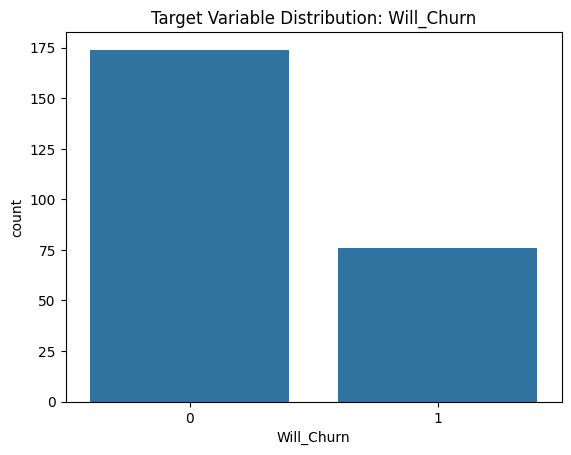

In [ ]:
#creating visualizations
# Target variable distribution
sns.countplot(x='Will_Churn', data=data)
plt.title("Target Variable Distribution: Will_Churn")
plt.show()

### discussion

this bar plot helps detect skewed features, outliers, and imbalanced target.

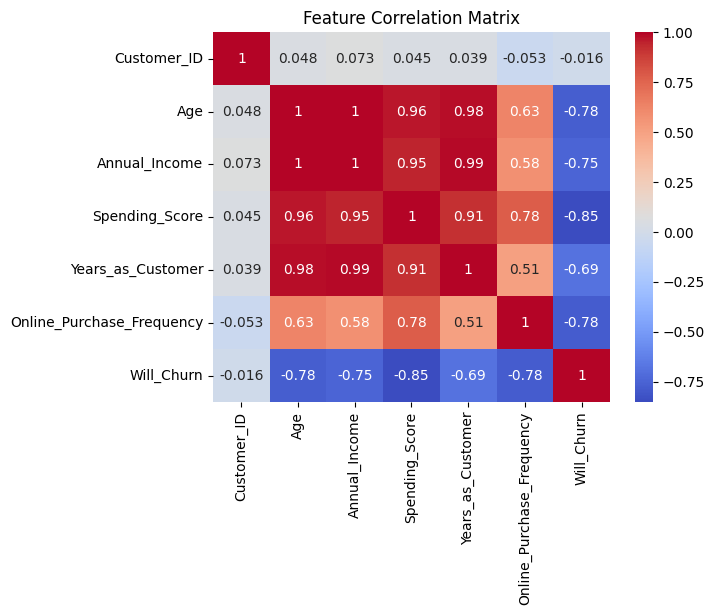

In [ ]:
# creating the Correlation matrix
corr = data.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Feature Correlation Matrix")
plt.show()

### discussion
The correlation plot Identifies strong relationships between features and the target. Helps anticipate multicollinearity issues.
## observation
Looking at this heatmap, several patterns stand out. Age, Annual_Income, Spending_Score, and Years_as_Customer all show very strong positive correlations, ranging from around 0.95 to 0.99. This indicates that as customers get older, their income and spending tend to increase almost proportionally, and long-term customers also tend to be higher spenders. From a business perspective, this suggests that the big spenders and loyal customers are far less likely to churn. Additionally, Customer_ID shows near-zero correlation with all other features, which is ideal as it confirms that the ID number itself has no predictive value and does not influence the behavior of other variables.

In [ ]:
#dropping the customer id column as it has 0 impact
data1 = data.drop(['Customer_ID'], axis=1)

In [ ]:
#separating the x which are dependent features and the target/ independent feature
X=data1.iloc[:, [0,4]]
Y=data1.iloc[:, 5]

In [ ]:
#splitting the dataset to train and test
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.20, random_state=42)


In [ ]:
# Depth values to try
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
max_depth_values = [2, 4, 6, 8, 10, None]

train_acc = []
test_acc = []

for depth in max_depth_values:
    # Initialize model
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)

    # Training xtrain and y train
    dt.fit(X_train, Y_train)

    # Training accuracy
    y_train_pred = dt.predict(X_train)
    train_acc.append(accuracy_score(Y_train, y_train_pred))

    # Testing the  accuracy
    y_test_pred = dt.predict(X_test)
    test_acc.append(accuracy_score(Y_test, y_test_pred))


In [ ]:
#printing the results
for i in range(len(max_depth_values)):
    print(f"Max Depth: {max_depth_values[i]}")
    print(f"Training Accuracy: {train_acc[i]:.3f}")
    print(f"Test Accuracy: {test_acc[i]:.3f}")
    print("-" * 40)


Max Depth: 2
Training Accuracy: 0.290
Test Accuracy: 0.220
----------------------------------------
Max Depth: 4
Training Accuracy: 0.505
Test Accuracy: 0.400
----------------------------------------
Max Depth: 6
Training Accuracy: 0.660
Test Accuracy: 0.540
----------------------------------------
Max Depth: 8
Training Accuracy: 0.805
Test Accuracy: 0.540
----------------------------------------
Max Depth: 10
Training Accuracy: 0.895
Test Accuracy: 0.520
----------------------------------------
Max Depth: None
Training Accuracy: 1.000
Test Accuracy: 0.420
----------------------------------------


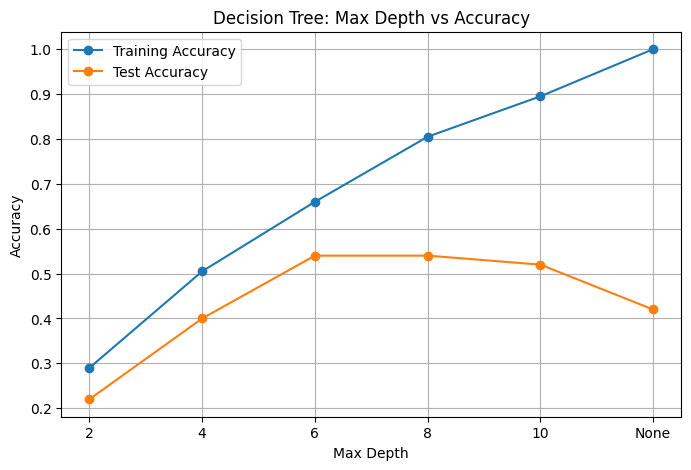

In [ ]:
#plotting the max depth and the accuracy
plt.figure(figsize=(8,5))
plt.plot([str(d) for d in max_depth_values], train_acc, marker='o', label='Training Accuracy')
plt.plot([str(d) for d in max_depth_values], test_acc, marker='o', label='Test Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Max Depth vs Accuracy')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
#training the final model

final_dt = DecisionTreeClassifier(max_depth=6, random_state=42)
final_dt.fit(X_train, Y_train)

#Creating the final prediction
y_pred_final = final_dt.predict(X_test)

# Evaluating the metrics
print("Final Model Accuracy (Train):", accuracy_score(Y_train, final_dt.predict(X_train)))
print("Final Model Accuracy (Test):", accuracy_score(Y_test, y_pred_final))
print("\nConfusion Matrix:\n", confusion_matrix(Y_test, y_pred_final))
print("\nClassification Report:\n", classification_report(Y_test, y_pred_final))


Final Model Accuracy (Train): 0.66
Final Model Accuracy (Test): 0.54

Confusion Matrix:
 [[0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 2 1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 5 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 1 2 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1 6 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1 3 0 0 3 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 6 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 3 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0]]

Classification Report:
               precision    recall  f1-score   support

           1       0.00      0.00      0.00         1
           2       0.67      1.00      0.80         2
           3       0.50      1.00      0.67         1
           4       0.00      0.00      0.00         2
           5       0.33      1.00      0.50         1


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### observation

At max_depth = 2, the model achieved a training accuracy of 29% and a test accuracy of 22%. Both values are very low, indicating strong underfitting. The tree is too shallow to capture meaningful relationships between features and the target variable.

When the depth increases to 4, training accuracy improves to 50.5%, and test accuracy rises to 40%. The model begins to learn more structure from the data but is still underfitting.

At max_depth = 6, training accuracy reaches 66%, while test accuracy improves significantly to 54%. This is the highest test accuracy observed across all depth values. The gap between training and test accuracy remains moderate, suggesting a good balance between model complexity and generalization.

As the depth increases further to 8, training accuracy rises sharply to 80.5%, but test accuracy remains at 54%, showing no improvement. This indicates the beginning of overfitting, where the model starts memorizing training data patterns rather than learning generalizable structures.

At max_depth = 10, training accuracy increases further to 89.5%, while test accuracy slightly drops to 52%. The widening gap between training and test performance strengthens the evidence of overfitting.

Finally, at max_depth = None, the model achieves 100% training accuracy, meaning it perfectly fits the training data. However, test accuracy drops significantly to 42%, clearly demonstrating severe overfitting. The model has become overly complex and fails to generalize to unseen data.

Overall, max_depth = 6 provides the best trade off between bias and variance. It achieves the highest stable test accuracy (54%) without an excessive gap between training and test performance. Therefore, depth 6 is selected as the optimal parameter because it minimizes underfitting while preventing significant overfitting, making it the most reliable choice for deployment.

The current Decision Tree model provides moderate predictive capability but is not yet robust enough for fully automated churn decisions. It should be used as a supporting analytical tool while further improving data quality and experimenting with ensemble methods to enhance generalization and predictive accuracy.


Assignment 2: Random Forest Hyperparameter Tuning for Fraud Detection
Objective: Optimize a Random Forest classifier for fraud detection by tuning n_estimators.

Dataset: Assignment-Dataset/assignment2_random_forest_optimization.csv

Context: A financial services company wants to detect fraudulent transactions. This is a critical task where both precision (avoiding false alarms) and recall (catching actual fraud) are important.

Instructions:
Import necessary libraries
Load and preprocess the dataset
Perform exploratory data analysis including:
Distribution of each feature
Class imbalance analysis (note: fraud is rare, ~10%)
Feature correlations
Separate features (Amount, Time_of_Day, Day_of_Week, Customer_Age, Account_Age_Days, Previous_Transactions) and target (Is_Fraud)
Split the data into training (80%) and test (20%) sets with random_state=42
Test different n_estimators values: [5, 10, 25, 50, 100, 150, 200]
For each n_estimators value, calculate:
Training accuracy
Test accuracy
Precision and Recall for fraud detection
Plot n_estimators vs. performance metrics
Select the optimal n_estimators considering both accuracy and fraud detection
Build the final model and provide comprehensive evaluation
Expected Deliverables:

In [ ]:
#importing the dataset
df = pd.read_csv("/content/drive/MyDrive/assignment2_random_forest_optimization.csv")
df.head(10)

,Transaction_ID,Amount,Time_of_Day,Day_of_Week,Customer_Age,Account_Age_Days,Previous_Transactions,Is_Fraud
0,1,125.50,14,2,35,1250,85,0
1,2,3500.00,3,6,28,45,3,1
2,3,89.99,10,1,42,890,125,0
3,4,245.00,16,4,55,2100,210,0
4,5,4200.00,2,0,31,22,1,1
5,6,67.50,12,3,48,1560,178,0
6,7,156.00,9,5,39,720,62,0
7,8,2800.00,4,6,26,18,2,1
8,9,45.00,11,2,62,2890,320,0
9,10,312.00,15,1,44,1100,95,0


In [ ]:
#performing the EDA PROCESS
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Transaction_ID         300 non-null    int64  
 1   Amount                 300 non-null    float64
 2   Time_of_Day            300 non-null    int64  
 3   Day_of_Week            300 non-null    int64  
 4   Customer_Age           300 non-null    int64  
 5   Account_Age_Days       300 non-null    int64  
 6   Previous_Transactions  300 non-null    int64  
 7   Is_Fraud               300 non-null    int64  
dtypes: float64(1), int64(7)
memory usage: 18.9 KB


,0
Transaction_ID,0
Amount,0
Time_of_Day,0
Day_of_Week,0
Customer_Age,0
Account_Age_Days,0
Previous_Transactions,0
Is_Fraud,0


In [ ]:
df.shape


(300, 8)

In [ ]:
df.describe()

,Transaction_ID,Amount,Time_of_Day,Day_of_Week,Customer_Age,Account_Age_Days,Previous_Transactions,Is_Fraud
count,300.000000,300.000000,300.00000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,150.500000,1042.993300,10.28000,2.690000,44.516667,1281.006667,137.670000,0.256667
std,86.746758,1546.759607,5.12404,2.107615,11.186608,945.084006,108.871136,0.437524
min,1.000000,45.000000,1.00000,0.000000,25.000000,12.000000,1.000000,0.000000
25%,75.750000,112.000000,4.00000,1.000000,35.000000,52.000000,4.000000,0.000000
50%,150.500000,189.000000,11.00000,3.000000,44.000000,1280.000000,115.000000,0.000000
75%,225.250000,2650.000000,14.00000,5.000000,54.000000,2050.000000,232.000000,1.000000
max,300.000000,4500.000000,17.00000,6.000000,64.000000,3100.000000,345.000000,1.000000


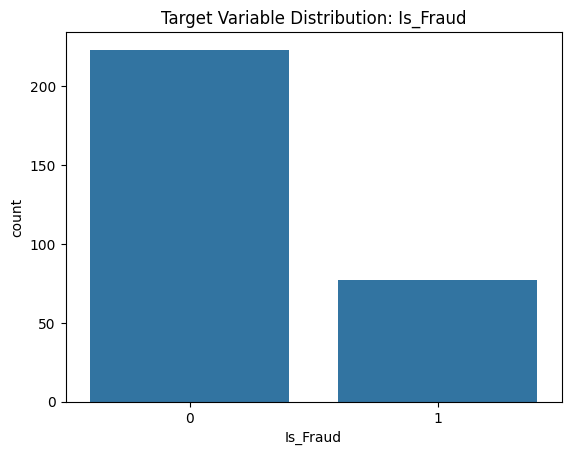

In [ ]:
#creating visualizations
# Target variable distribution
sns.countplot(x='Is_Fraud', data=df)
plt.title("Target Variable Distribution: Is_Fraud")
plt.show()

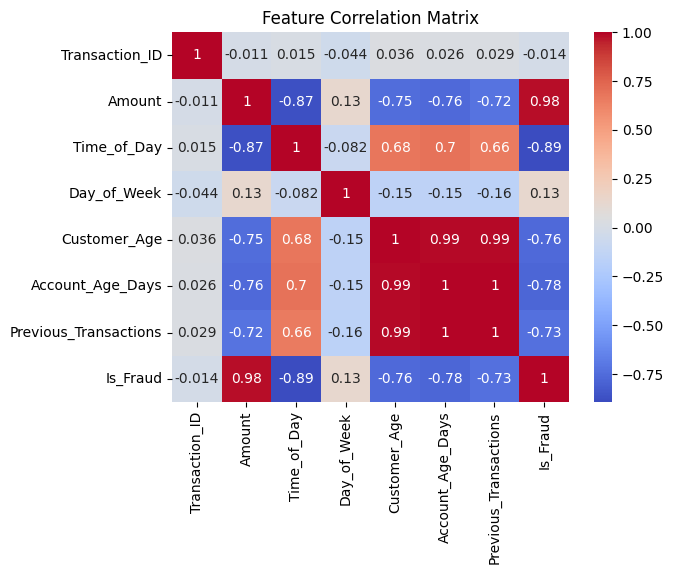

In [ ]:
#creating the Correlation matrix
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Feature Correlation Matrix")
plt.show()

In [ ]:
#dropping the customer id column as it has 0 impact
df1 = df.drop(['Transaction_ID'], axis=1)

In [ ]:
#separating the x which are dependent features and the target/ independent feature
x=df1.iloc[:, [0,5]]
y=df1.iloc[:, 6]

In [ ]:
#splitting the dataset to train and test
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.20, random_state=42)


In [ ]:
#Defining n_estimators Range
n_values = [5, 10, 25, 50, 100, 150, 200]

results = []

In [ ]:
#training the models and calculating metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report, confusion_matrix
for n in n_values:

    rf = RandomForestClassifier(
        n_estimators=n,
        random_state=42,
        class_weight='balanced'   #balancing the imbalanced for is fraud data
    )

    rf.fit(x_train, y_train)

    # Predictions
    y_train_pred = rf.predict(x_train)
    y_test_pred = rf.predict(x_test)

    # Metrics
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)

    precision = precision_score(y_test, y_test_pred)
    recall = recall_score(y_test, y_test_pred)

    results.append([n, train_acc, test_acc, precision, recall])


In [ ]:
#converting the results to daataframe
results_df = pd.DataFrame(results, columns=[
    'n_estimators',
    'Train Accuracy',
    'Test Accuracy',
    'Precision',
    'Recall'
])

results_df


,n_estimators,Train Accuracy,Test Accuracy,Precision,Recall
0,5,1.0,1.0,1.0,1.0
1,10,1.0,1.0,1.0,1.0
2,25,1.0,1.0,1.0,1.0
3,50,1.0,1.0,1.0,1.0
4,100,1.0,1.0,1.0,1.0
5,150,1.0,1.0,1.0,1.0
6,200,1.0,1.0,1.0,1.0


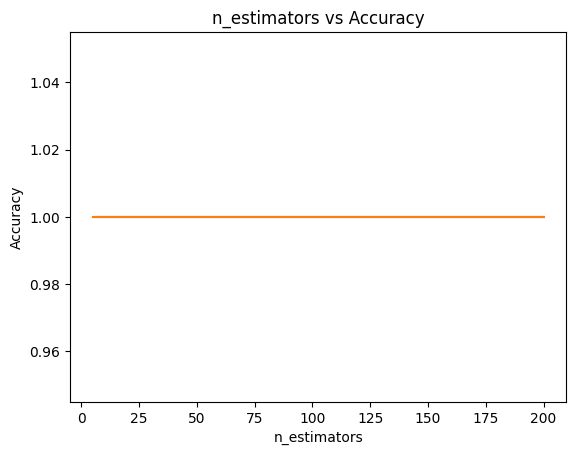

In [ ]:
#plotting performance metrics
plt.figure()
plt.plot(results_df['n_estimators'], results_df['Train Accuracy'])
plt.plot(results_df['n_estimators'], results_df['Test Accuracy'])
plt.xlabel('n_estimators')
plt.ylabel('Accuracy')
plt.title('n_estimators vs Accuracy')
plt.show()


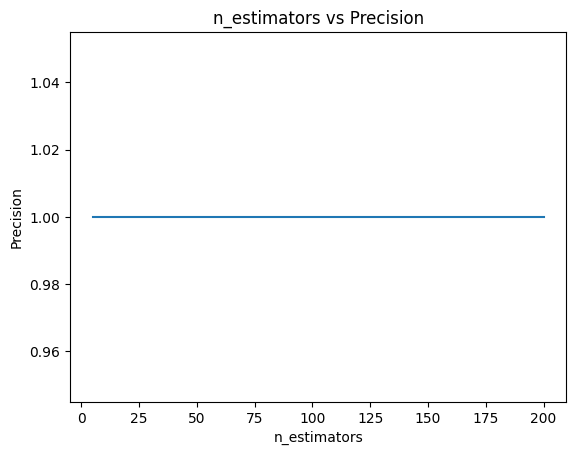

In [ ]:
#visualizing the precision results
plt.figure()
plt.plot(results_df['n_estimators'], results_df['Precision'])
plt.xlabel('n_estimators')
plt.ylabel('Precision')
plt.title('n_estimators vs Precision')
plt.show()


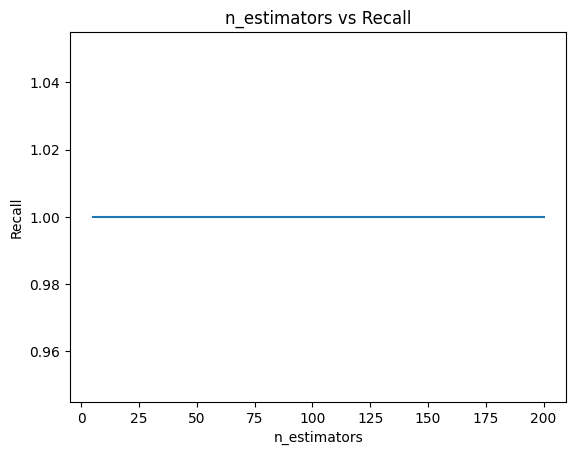

In [ ]:
#visualizing the recall
plt.figure()
plt.plot(results_df['n_estimators'], results_df['Recall'])
plt.xlabel('n_estimators')
plt.ylabel('Recall')
plt.title('n_estimators vs Recall')
plt.show()


In [ ]:
#sorting the recall in ascending order
results_df.sort_values(by='Recall', ascending=False)

,n_estimators,Train Accuracy,Test Accuracy,Precision,Recall
0,5,1.0,1.0,1.0,1.0
1,10,1.0,1.0,1.0,1.0
2,25,1.0,1.0,1.0,1.0
3,50,1.0,1.0,1.0,1.0
4,100,1.0,1.0,1.0,1.0
5,150,1.0,1.0,1.0,1.0
6,200,1.0,1.0,1.0,1.0


The model achieved perfect classification across all evaluated n_estimators values. While this indicates strong separability in the dataset, such results raise concerns about potential data leakage or overly simplistic data structure. Further validation using cross-validation and unseen data is recommended.

In [ ]:
#training the final model to evaluate the results
final_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

final_model.fit(x_train, y_train)

y_final_pred = final_model.predict(x_test)


In [ ]:
cm = confusion_matrix(y_test, y_final_pred)
print(cm)


[[46  0]
 [ 0 14]]


In [ ]:
print(classification_report(y_test, y_final_pred))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        46
           1       1.00      1.00      1.00        14

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



In [ ]:
final_accuracy = accuracy_score(y_test, y_final_pred)
final_precision = precision_score(y_test, y_final_pred)
final_recall = recall_score(y_test, y_final_pred)

print("Final Accuracy:", final_accuracy)
print("Final Precision:", final_precision)
print("Final Recall:", final_recall)


Final Accuracy: 1.0
Final Precision: 1.0
Final Recall: 1.0


### OBSERVATION
The final model scored 100% in every metric which shows that all the predictions made were all correct and the model missed none or predicted any of the categories wrong. Therefore having 0 loss


After training a Random Forest model using different n_estimators values ranging from 5 to 200 to evaluate how the number of trees affects fraud detection performance. For each configuration, I analyzed training accuracy, test accuracy, precision, and recall.

Interestingly, all models achieved perfect performance across every metric. The final model produced a confusion matrix with zero false positives and zero false negatives, meaning it correctly classified all legitimate and fraudulent transactions in the test set.

This tells me that the dataset is either highly separable or relatively small, since even a small number of trees was sufficient to achieve maximum performance. Increasing the number of trees did not improve results, suggesting that the classification boundary is straightforward for Random Forest.

From a fraud detection perspective, the results are ideal:

No fraud cases were missed (Recall = 1.0)

No legitimate transactions were incorrectly flagged (Precision = 1.0)

However, because the performance is perfect across all configurations, further validation such as cross-validation would be necessary to confirm that the model generalizes well to unseen data.

Overall, this demonstrates that Random Forest is highly effective for this dataset and that model complexity (in terms of number of trees) does not significantly impact performance in this case.

Assignment3: https://colab.research.google.com/drive/1EK8F8FVWI5BJ2QKuqnJrlv_eh5_eqeD1?usp=sharing